In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)

In [35]:
df = pd.read_csv("retail_sales_dataset.csv")
df.columns = df.columns.str.strip()
print(df.columns.to_list())
df.head()

['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [36]:
df["Date"] = pd.to_datetime(df["Date"])
print("Date dtype:", df["Date"].dtype)


Date dtype: datetime64[us]


In [38]:
num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]

stats = pd.DataFrame({
    "Mean": df[num_cols].mean(),
    "Median": df[num_cols].median(),
    "Mode": df[num_cols].mode().iloc[0],
    "Std Dev": df[num_cols].std(),
})
stats.round(2)

,Mean,Median,Mode,Std Dev
Age,41.39,42.0,43.0,13.68
Quantity,2.51,3.0,4.0,1.13
Price per Unit,179.89,50.0,50.0,189.68
Total Amount,456.00,135.0,50.0,560.00


In [40]:
df["Date"].head()

0   2023-11-24
1   2023-02-27
2   2023-01-13
3   2023-05-21
4   2023-05-06
Name: Date, dtype: datetime64[us]

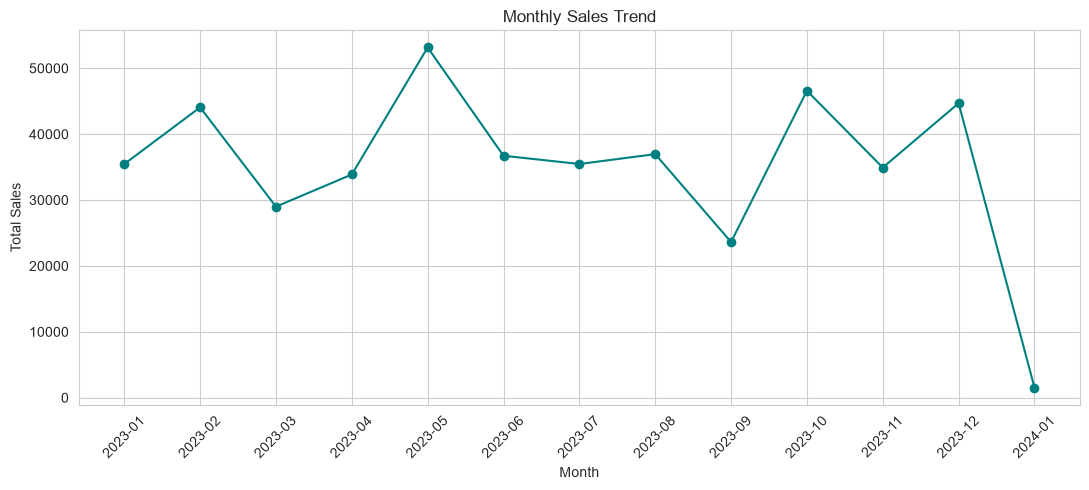

In [41]:
monthly_sales = df.groupby(df["Date"].dt.to_period("M"))["Total Amount"].sum()

plt.figure(figsize=(11, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o", color="teal")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [42]:
monthly_sales

Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

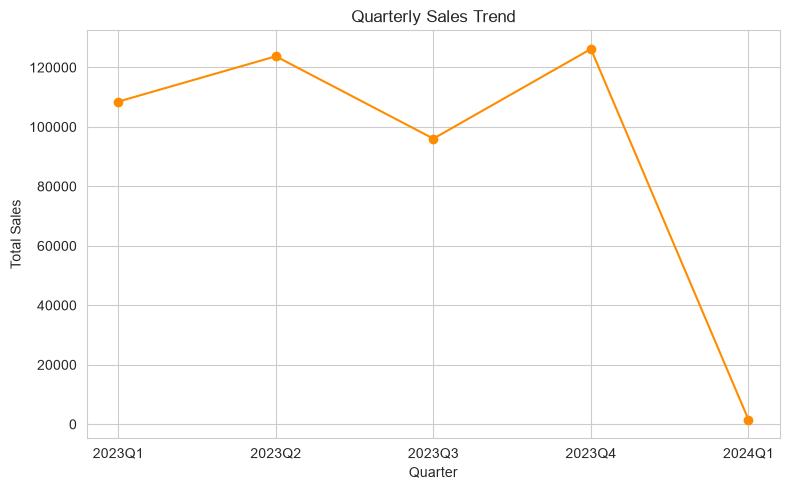

In [43]:
quarterly_sales = df.groupby(df["Date"].dt.to_period("Q"))["Total Amount"].sum()

plt.figure(figsize=(8, 5))
plt.plot(quarterly_sales.index.astype(str), quarterly_sales.values, marker="o", color="darkorange")
plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [44]:
quarterly_sales

Date
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64

In [45]:
bins = [17, 25, 35, 45, 55, 65]
labels = ["18-25", "26-35", "36-45", "46-55", "56-65"]
df["Age Group"] = pd.cut(df["Age"], bins=bins, labels=labels)

df["Age Group"].value_counts().sort_index()

Age Group
18-25    169
26-35    205
36-45    202
46-55    229
56-65    195
Name: count, dtype: int64

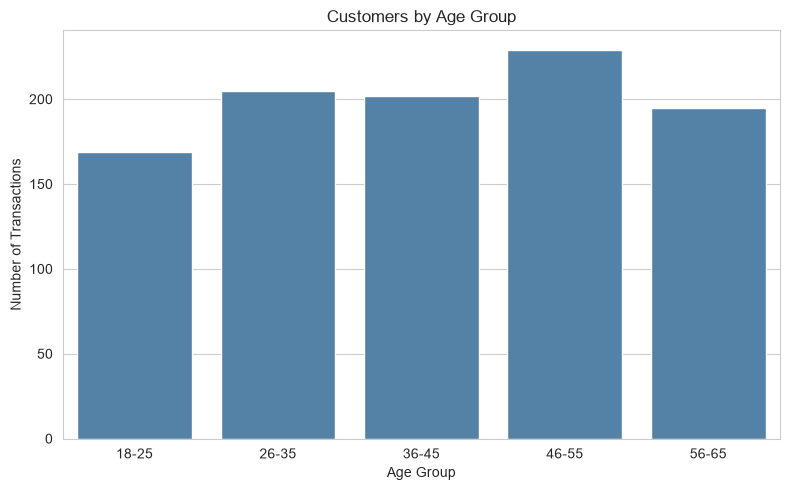

In [46]:
age_counts = df["Age Group"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(x=age_counts.index, y=age_counts.values, color="steelblue")
plt.title("Customers by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

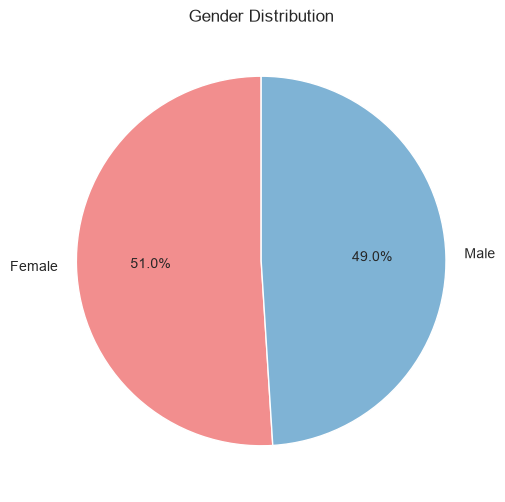

Gender
Female    510
Male      490
Name: count, dtype: int64

In [47]:
#gender brekdown counts
gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(gender_counts.values, labels=gender_counts.index, autopct="%1.1f%%",
        colors=["#f28e8e", "#7fb3d5"], startangle=90)
plt.title("Gender Distribution")
plt.show()

gender_counts

In [48]:
#gender ke hisab se spending total
gender_sales = df.groupby("Gender")["Total Amount"].agg(["sum", "mean"]).round(2)
gender_sales

,sum,mean
Gender,,
Female,232840,456.55
Male,223160,455.43


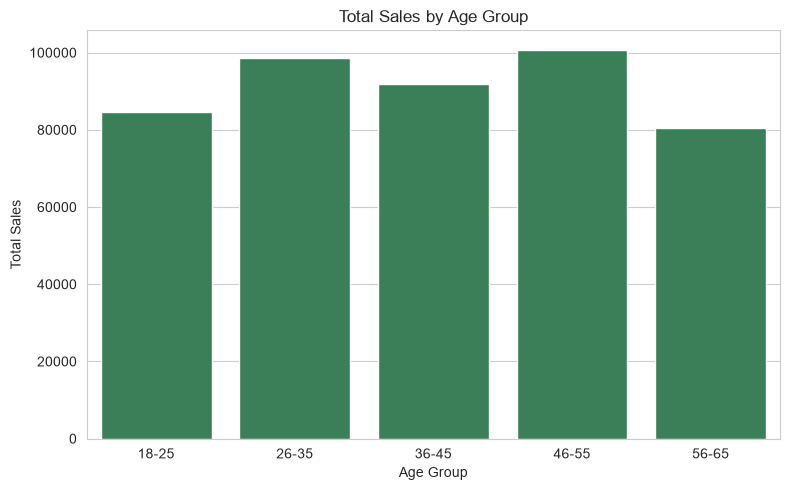

In [49]:
#age group ke hisab se total sales
age_sales = df.groupby("Age Group", observed=True)["Total Amount"].sum()

plt.figure(figsize=(8, 5))
sns.barplot(x=age_sales.index, y=age_sales.values, color="seagreen")
plt.title("Total Sales by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

C:\Users\Abc\AppData\Local\Temp\ipykernel_12736\2343690059.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_revenue.index, y=category_revenue.values, palette="viridis")


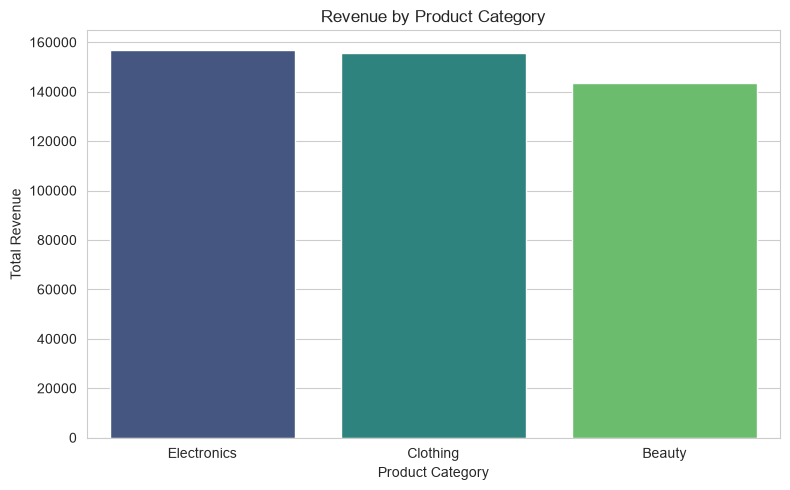

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

In [50]:
#revenue by product cataegory
category_revenue = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=category_revenue.index, y=category_revenue.values, palette="viridis")
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

category_revenue

In [51]:
#best selling category
category_qty = df.groupby("Product Category")["Quantity"].sum().sort_values(ascending=False)
category_qty

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64

In [52]:
#top 10 cutomers by spending
top_customers = (df.groupby("Customer ID")["Total Amount"].sum()
                   .sort_values(ascending=False).head(10))
top_customers

Customer ID
CUST015    2000
CUST412    2000
CUST970    2000
CUST547    2000
CUST281    2000
CUST416    2000
CUST420    2000
CUST927    2000
CUST447    2000
CUST342    2000
Name: Total Amount, dtype: int64

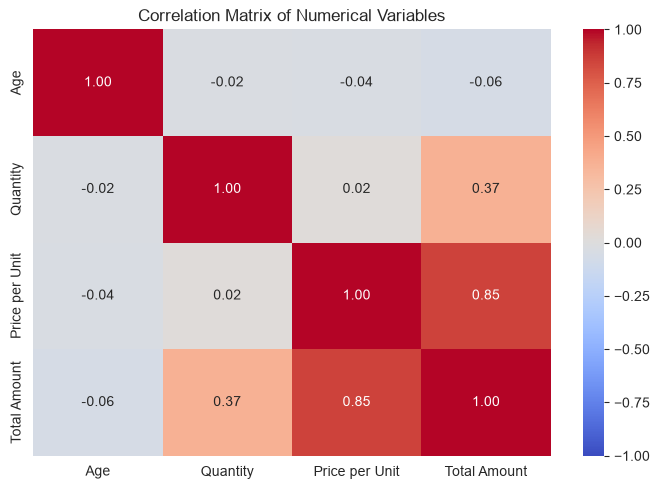

In [55]:
#heatmap for correlation
corr = df[["Age", "Quantity", "Price per Unit", "Total Amount"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()

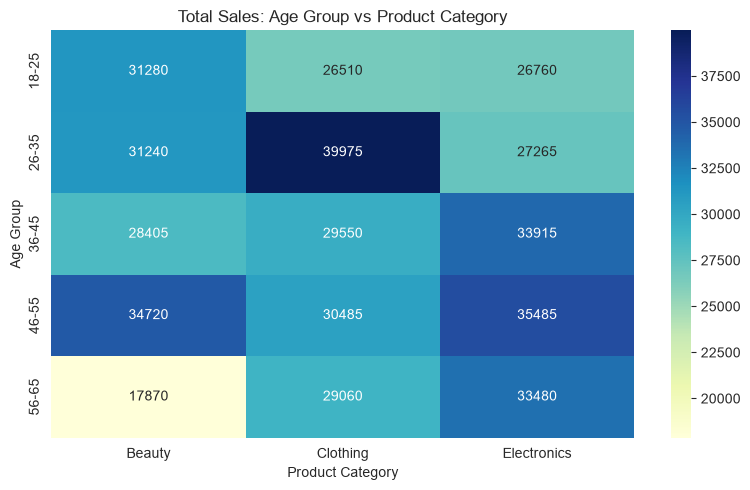

In [56]:
#extra visualizations
pivot = df.pivot_table(values="Total Amount", index="Age Group",
                       columns="Product Category", aggfunc="sum", observed=True)

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Total Sales: Age Group vs Product Category")
plt.tight_layout()
plt.show()

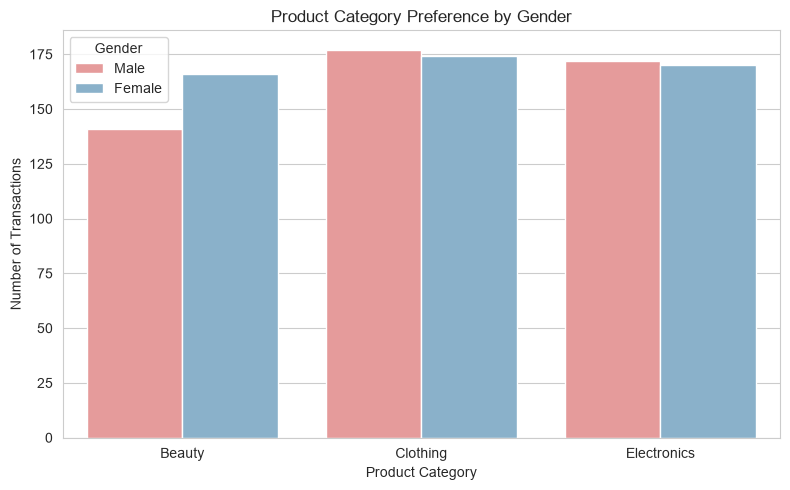

In [57]:
#gender  and category ka relations
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Product Category", hue="Gender", palette=["#f28e8e", "#7fb3d5"])
plt.title("Product Category Preference by Gender")
plt.xlabel("Product Category")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

In [58]:
#markdown and conclusion and bussiness reccomendations
## Conclusion & Recommendations

#**Key findings:**
#1. ___
#2. ___
#3. ___

#**Business recommendations:**
#1. **___ category ko promote karo**: kyunki ___ category me sabse zyada revenue (___) aaya hai.
#2. **___ age group ko target karo**: kyunki ye group total sales me sabse aage hai (___), uske liye special offers ya campaigns chalao.
#3. **Sales ke slow months me offers do**: ___ aur ___ months me sales kam rahi, wahan discounts ya festive campaigns chalao.

#**Limitation:** Dataset me product names/IDs nahi hain, isliye product-level analysis ki jagah category-level analysis kiya gaya.